# AMPC Cart-Pole — Baseline Float32 conforme al paper y código original

Este notebook establece el **baseline Float32** antes de cuantizar, siguiendo el testing original de Hose, Gräfe y Trimpe (L4DC 2024).

Se reproducen:

- dinámica `dynamic.py`;
- $\(T_s = 160\)$ ms;
- 16 s de simulación = 100 pasos;
- entrada saturada en $\([-9,9]\)$ V;
- integración con `odeint`;
- 200 condiciones iniciales con `jax.random.PRNGKey(100)`;
- $\(y_0\in[-0.35,0.35]\)$, $\(\alpha_0\in[-\pi,\pi]\)$;
- velocidades iniciales nulas;
- restricción global $\(|y|<0.4\)$;
- criterio final en las últimas 10 muestras: $\(|y|<0.1\)$, $\(|\alpha|<0.17\)$;
- cálculo de `success rate`.

Además se añaden métricas complementarias para la tesis, separadas del criterio original.

In [1]:
from pathlib import Path
import math, time, pickle, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import equinox as eqx
from scipy.integrate import odeint

jax.config.update("jax_platform_name", "cpu")
np.set_printoptions(precision=6, suppress=True)

print("JAX:", jax.__version__)
print("Equinox:", eqx.__version__)
print("Device:", jax.devices())

JAX: 0.6.2
Equinox: 0.13.8
Device: [CpuDevice(id=0)]


## 1. Rutas

In [5]:
DATASET_DIR = Path(r"FinalAMPCPendulumDataset")
X_PATH  = DATASET_DIR / "X.csv"
U_PATH  = DATASET_DIR / "U.csv"
X0_PATH = DATASET_DIR / "X0.csv"

# Política nominal pi_NN: el paper especifica 5 capas x 50 neuronas.
MODEL_DIR = Path(r"model")
MODEL_PATH = MODEL_DIR / "model.eqx"
PARAMS_PATH = MODEL_DIR / "params.yaml"
NORMALIZATION_PATH = MODEL_DIR / "normalization_reconstructed.pkl"

for p in [X_PATH, U_PATH, X0_PATH, MODEL_PATH, PARAMS_PATH, NORMALIZATION_PATH]:
    print(f"{p.name:16s} -> {'OK' if p.exists() else 'NO ENCONTRADO'}")

X.csv            -> OK
U.csv            -> OK
X0.csv           -> OK
model.eqx        -> OK
params.yaml      -> OK
normalization_reconstructed.pkl -> OK


## 2. Leer `params.yaml` y verificar que sea la política nominal

In [7]:
with open(PARAMS_PATH, "r", encoding="utf-8") as f:
    params = yaml.safe_load(f)

for k in ["num_layers", "num_neurons", "num_sys_states",
          "num_sys_inputs", "num_aug_params", "activation_function"]:
    print(f"{k:22s}: {params.get(k)}")

if params.get("train_aug", False):
    print("⚠ Este modelo está marcado como red aumentada.")
else:
    print("✓ Modelo candidato a política nominal π_NN.")

num_layers            : 8
num_neurons           : 50
num_sys_states        : 4
num_sys_inputs        : 1
num_aug_params        : 5
activation_function   : tanh
✓ Modelo candidato a política nominal π_NN.


## 3. Reconstruir y cargar `model.eqx`

In [8]:
def init_weight(dim_in, dim_out, key):
    stdv = 1.0 / math.sqrt(dim_out)
    return jax.random.uniform(key, (dim_out, dim_in)) * 2 * stdv - stdv

def init_bias(dim_out, key):
    stdv = 1.0 / math.sqrt(dim_out)
    return jax.random.uniform(key, (dim_out,)) * 2 * stdv - stdv

class FullyConnectedLayer(eqx.Module):
    weight: jax.Array
    bias: jax.Array
    activation: callable
    activation_function_name: str
    input_dim: int
    output_dim: int

    def __init__(self, input_dim, output_dim, rng_key, activation_function="linear"):
        kw, kb = jax.random.split(rng_key)
        self.weight = init_weight(input_dim, output_dim, kw)
        self.bias = init_bias(output_dim, kb)
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.activation_function_name = activation_function
        if activation_function == "linear":
            self.activation = None
        elif activation_function == "tanh":
            self.activation = jax.nn.tanh
        elif activation_function == "relu":
            self.activation = jax.nn.relu
        else:
            raise ValueError(activation_function)

    def __call__(self, x):
        y = self.weight @ x + self.bias
        return y if self.activation is None else self.activation(y)

class MLP(eqx.Module):
    layers: list

    def __init__(self, layer_structure, rng_key, activation_function="tanh"):
        keys = jax.random.split(rng_key, len(layer_structure)-1)
        layers = []
        for i in range(len(layer_structure)-1):
            last = i == len(layer_structure)-2
            layers.append(
                FullyConnectedLayer(
                    layer_structure[i],
                    layer_structure[i+1],
                    keys[i],
                    "linear" if last else activation_function
                )
            )
        self.layers = layers

    def __call__(self, x):
        def one(z):
            for layer in self.layers:
                z = layer(z)
            return z
        return jax.vmap(one)(x) if x.ndim == 2 else one(x)

class AMPCNN(eqx.Module):
    output_dim: int
    num_sys_states: int
    num_sys_inputs: int
    num_aug_params: int
    neural_network: object

    def __init__(self, num_layers, num_neurons, num_sys_states,
                 num_sys_inputs, num_aug_params, rng_key,
                 activation_function="tanh"):
        self.output_dim = num_sys_inputs
        self.num_sys_states = num_sys_states
        self.num_sys_inputs = num_sys_inputs
        self.num_aug_params = num_aug_params

        structure = [num_sys_states]
        for _ in range(num_layers - 1):
            structure.append(num_neurons)
        structure.append(num_sys_inputs)

        self.neural_network = MLP(structure, rng_key, activation_function)

    @eqx.filter_jit
    def __call__(self, x):
        return self.neural_network(x)

init_key = jax.random.PRNGKey(1)

template = AMPCNN(
    num_layers=params["num_layers"],
    num_neurons=params["num_neurons"],
    num_sys_states=params["num_sys_states"],
    num_sys_inputs=params["num_sys_inputs"],
    num_aug_params=params["num_aug_params"],
    rng_key=init_key,
    activation_function=params["activation_function"],
)

model = eqx.tree_deserialise_leaves(str(MODEL_PATH), template)
print("✓ model.eqx cargado")

✓ model.eqx cargado


## 4. Normalización original o reconstruida

In [9]:
def stats_media_maxabs(path, columnas, chunksize=50000):
    suma = None
    maxabs = None
    n = 0
    for chunk in pd.read_csv(path, header=None, usecols=columnas,
                             chunksize=chunksize, dtype=np.float64):
        a = chunk.to_numpy()
        if suma is None:
            suma = np.zeros(a.shape[1])
            maxabs = np.zeros(a.shape[1])
        suma += a.sum(axis=0)
        maxabs = np.maximum(maxabs, np.max(np.abs(a), axis=0))
        n += len(a)
    return suma/n, maxabs

if NORMALIZATION_PATH.exists():
    with open(NORMALIZATION_PATH, "rb") as f:
        normalization = pickle.load(f)
    NORMALIZATION_SOURCE = "normalization.p ORIGINAL"
else:
    mu_x, scale_x = stats_media_maxabs(X0_PATH, [0,1,2,3])
    mu_u, scale_u = stats_media_maxabs(U_PATH, [0])
    normalization = {"x": (mu_x, scale_x), "u": (mu_u, scale_u)}
    NORMALIZATION_SOURCE = "RECONSTRUIDA DESDE DATASET"

print("Fuente:", NORMALIZATION_SOURCE)
print("x:", normalization["x"])
print("u:", normalization["u"])

Fuente: normalization.p ORIGINAL
x: (array([ 0.000067,  0.004411,  0.000187, -0.00378 ]), array([0.349999, 6.28318 , 1.199999, 9.999998]))
u: (array([-0.007703]), array([9.]))


In [10]:
def normalize(data, p):
    return (data - p[0]) / p[1]

def denormalize(data, p):
    return data * p[1] + p[0]

def call_control_nominal(x):
    x = np.asarray(x, dtype=np.float32)
    xn = normalize(x, normalization["x"])
    un = model(jnp.asarray(xn, dtype=jnp.float32))
    u = denormalize(np.asarray(un), normalization["u"])
    return np.clip(np.asarray(u).reshape(-1), -9.0, 9.0)

## 5. Dinámica original de `dynamic.py`

In [11]:
M_cart_opt = 0.506
m_rod_opt = 0.23
L_rod_opt = 0.6393037858519218
J_mot_eq_opt = 0.2153426947227305
AB_opt = -3.9610232930789304
AC_opt = 1.3002429170001302
B_eq_opt = 3.961023945944119
B_p_opt = 0.0002073799633807001

def f_rod_generic(x, u, m_add=0.02, M_cart=M_cart_opt,
                  m_rod=m_rod_opt, L_rod=L_rod_opt,
                  J_mot_eq=J_mot_eq_opt, AB=AB_opt, AC=AC_opt,
                  B_eq=B_eq_opt, Bp=B_p_opt):
    g = 9.81
    L = L_rod
    m = m_add + m_rod
    l = (L/2*m_rod + L*m_add) / m
    J_rod = (m_rod * L**2) / 12
    J = J_rod + m_add * L**2
    M = M_cart + J_mot_eq

    h1 = M + m
    h2 = m*l
    h4 = m*l**2 + J
    h7 = m*l*g

    theta = x[1]
    v1 = x[2]
    dtheta = x[3]
    Vm = float(np.asarray(u).reshape(-1)[0])

    F = AB*v1 + AC*Vm
    c = np.cos(theta)
    s = np.sin(theta)
    den = h2**2*c**2 - h1*h4

    return np.array([
        v1,
        dtheta,
        (h2*h4*dtheta**2*s - h2*h7*c*s
         + h4*(F-B_eq*v1) - h2*c*Bp*dtheta) / (-den),
        (h2**2*dtheta**2*c*s - h1*h7*s
         + h2*c*(F-B_eq*v1) + h1*Bp*dtheta) / den
    ], dtype=np.float64)

def f_rod_generic_m(x, u, p):
    return f_rod_generic(
        x, u,
        m_add=0.02 + p[0],
        M_cart=M_cart_opt + p[2],
        AB=AB_opt + p[1],
        AC=AC_opt + p[3],
        Bp=B_p_opt + p[4]
    )

## 6. Simulador original: `odeint`, 160 ms

In [12]:
DT = 160e-3
N_SIM = int(16 / DT)
P_NOMINAL = [0,0,0,0,0]

class Simulator:
    def __init__(self, timestep, f):
        self.dt = timestep
        self.N = 1
        self.f = f

    def run(self, x0, u0):
        def rhs(y, t, u_const):
            return self.f(y, u_const)
        traj = odeint(
            rhs,
            np.asarray(x0, dtype=np.float64),
            np.linspace(0, self.dt, self.N+1),
            args=(u0,)
        )
        return traj[-1]

def f_true_nominal(x, u):
    return f_rod_generic_m(x, u, P_NOMINAL)

sim_nominal = Simulator(DT, f_true_nominal)

print("Ts:", DT, "s")
print("N:", N_SIM)
print("Tiempo total:", N_SIM*DT, "s")

Ts: 0.16 s
N: 100
Tiempo total: 16.0 s


## 7. Criterio exacto de éxito del `run_testing.py`

In [13]:
def mod_pendulum_np(X):
    X = np.asarray(X, dtype=np.float64).copy()
    X[...,1] = (X[...,1] + np.pi) % (2*np.pi) - np.pi
    return X

def check_constraints_original(X):
    X = mod_pendulum_np(X)
    const = np.array([0.4, 100.0, 100.0, 100.0])
    return bool(np.all((-const < X) & (X < const)))

def check_final_state_constraints_original(X):
    X = mod_pendulum_np(X)
    const = np.array([0.1, 0.17, 100.0, 170.0])
    return bool(np.all((-const < X[-10:]) & (X[-10:] < const)))

def success_original(X):
    return check_constraints_original(X) and check_final_state_constraints_original(X)

## 8. Closed-loop nominal Float32

In [14]:
def simulate_closed_loop_nominal(x0, n_steps=N_SIM):
    X = np.zeros((n_steps+1, 4), dtype=np.float64)
    U = np.zeros(n_steps, dtype=np.float64)
    X[0] = x0

    for k in range(n_steps):
        # Igual que run_tester_round(): sin wrap del ángulo antes del controlador.
        u = call_control_nominal(X[k])
        U[k] = float(u[0])
        X[k+1] = sim_nominal.run(X[k], np.array([U[k]]))
    return X, U

## 9. Prueba individual de 16 s

In [15]:
X0_DEMO = np.array([0.0, np.pi, 0.0, 0.0])
X_demo, U_demo = simulate_closed_loop_nominal(X0_DEMO)

print("Estado final:", X_demo[-1])
print("Restricción global:", check_constraints_original(X_demo))
print("Criterio final:", check_final_state_constraints_original(X_demo))
print("ÉXITO:", success_original(X_demo))

Estado final: [ 0.023051 -0.007851  0.099362 -0.140212]
Restricción global: True
Criterio final: True
ÉXITO: True


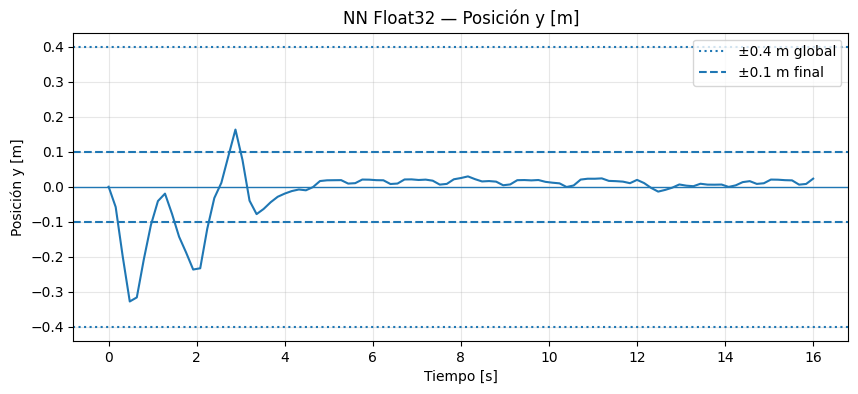

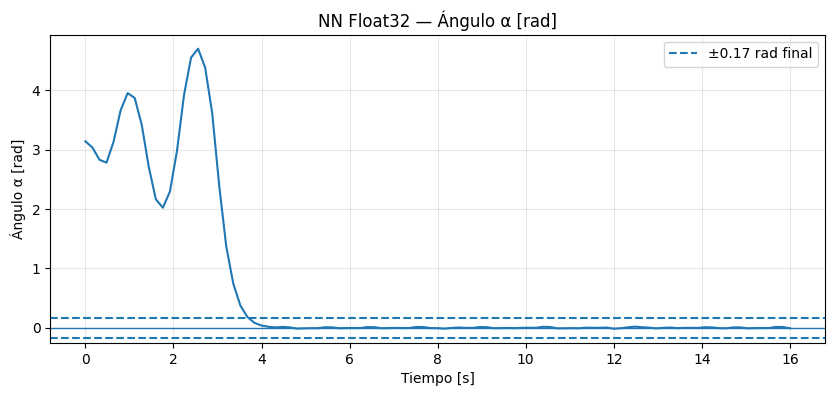

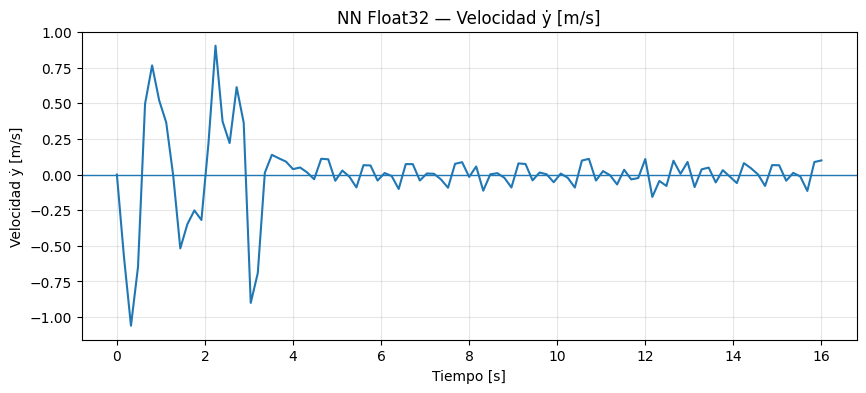

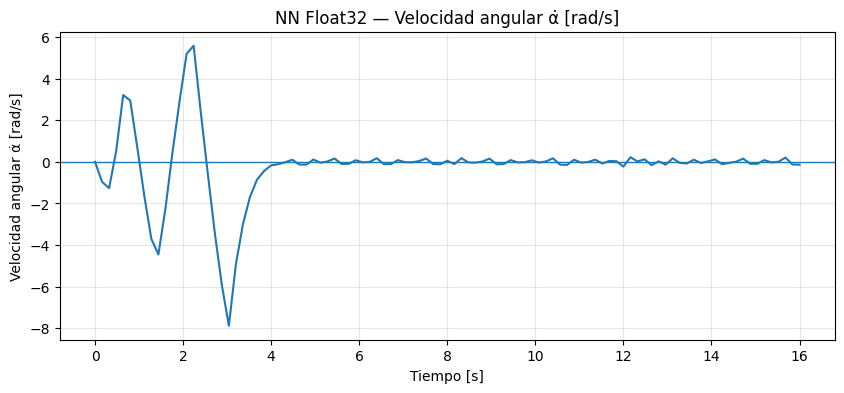

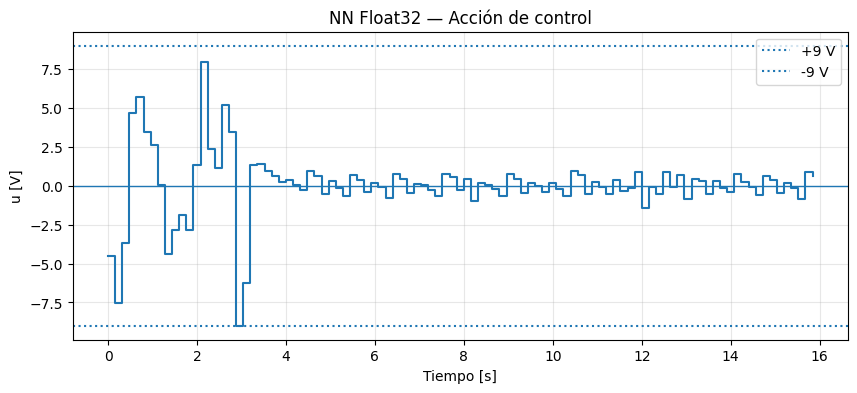

In [16]:
labels = [
    "Posición y [m]",
    "Ángulo α [rad]",
    "Velocidad ẏ [m/s]",
    "Velocidad angular α̇ [rad/s]"
]
tx = np.arange(len(X_demo))*DT
tu = np.arange(len(U_demo))*DT

for i, lab in enumerate(labels):
    plt.figure(figsize=(10,4))
    plt.plot(tx, X_demo[:,i])
    plt.axhline(0, linewidth=1)

    if i == 0:
        plt.axhline(0.4, linestyle=":", label="±0.4 m global")
        plt.axhline(-0.4, linestyle=":")
        plt.axhline(0.1, linestyle="--", label="±0.1 m final")
        plt.axhline(-0.1, linestyle="--")
        plt.legend()

    if i == 1:
        plt.axhline(0.17, linestyle="--", label="±0.17 rad final")
        plt.axhline(-0.17, linestyle="--")
        plt.legend()

    plt.xlabel("Tiempo [s]")
    plt.ylabel(lab)
    plt.title(f"NN Float32 — {lab}")
    plt.grid(True, alpha=0.3)
    plt.show()

plt.figure(figsize=(10,4))
plt.step(tu, U_demo, where="post")
plt.axhline(9, linestyle=":", label="+9 V")
plt.axhline(-9, linestyle=":", label="-9 V")
plt.axhline(0, linewidth=1)
plt.xlabel("Tiempo [s]")
plt.ylabel("u [V]")
plt.title("NN Float32 — Acción de control")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 10. Generar las 200 condiciones iniciales exactamente como los autores

In [17]:
NUM_INIT_POINTS = 200

def get_random_init_points_original(num=NUM_INIT_POINTS):
    maxval = jnp.array([0.35, jnp.pi, 0.0, 0.0])
    return np.asarray(
        jax.random.uniform(
            jax.random.PRNGKey(100),
            (num,4),
            minval=-maxval,
            maxval=maxval
        )
    )

X0_TEST = get_random_init_points_original()

print(X0_TEST.shape)
print(X0_TEST[:5])

(200, 4)
[[-0.118572 -2.505683  0.        0.      ]
 [ 0.314946 -1.391174  0.        0.      ]
 [ 0.003008  2.798644  0.        0.      ]
 [ 0.132619 -1.162783  0.        0.      ]
 [-0.01592   1.047053  0.        0.      ]]


## 11. Success Rate Float32

In [18]:
def evaluar_success_rate_float32(X0_test=X0_TEST):
    registros = []
    exitos = 0
    t0 = time.perf_counter()

    for i, x0 in enumerate(X0_test):
        X_i, U_i = simulate_closed_loop_nominal(x0)

        c_ok = check_constraints_original(X_i)
        f_ok = check_final_state_constraints_original(X_i)
        ok = c_ok and f_ok
        exitos += int(ok)

        Xm = mod_pendulum_np(X_i)

        registros.append({
            "id": i,
            "success": ok,
            "constraints_ok": c_ok,
            "final_state_ok": f_ok,
            "y0": x0[0],
            "alpha0": x0[1],
            "y_final": Xm[-1,0],
            "alpha_final": Xm[-1,1],
            "ydot_final": Xm[-1,2],
            "alphadot_final": Xm[-1,3],
            "max_abs_y": np.max(np.abs(Xm[:,0])),
            "max_abs_alpha": np.max(np.abs(Xm[:,1])),
            "u_min": np.min(U_i),
            "u_max": np.max(U_i),
            "saturated_samples": int(np.sum(np.isclose(np.abs(U_i), 9.0, atol=1e-5))),
            "sum_u2": float(np.sum(U_i**2)),
            "TV_u": float(np.sum(np.abs(np.diff(U_i))))
        })

    elapsed = time.perf_counter() - t0
    df = pd.DataFrame(registros)
    resumen = {
        "Modelo": "Float32",
        "N": len(X0_test),
        "Éxitos": exitos,
        "Fallos": len(X0_test)-exitos,
        "Success_Rate": exitos/len(X0_test),
        "Success_Rate_%": 100*exitos/len(X0_test),
        "Tiempo_evaluacion_s": elapsed
    }
    return df, resumen

df_runs_float32, resumen_float32 = evaluar_success_rate_float32()
display(pd.DataFrame([resumen_float32]))

,Modelo,N,Éxitos,Fallos,Success_Rate,Success_Rate_%,Tiempo_evaluacion_s
0,Float32,200,194,6,0.97,97.0,27.291593


## 12. Diagnóstico de fallos y mapa de condiciones iniciales

Fallos por restricción global: 0
Fallos por criterio final: 6


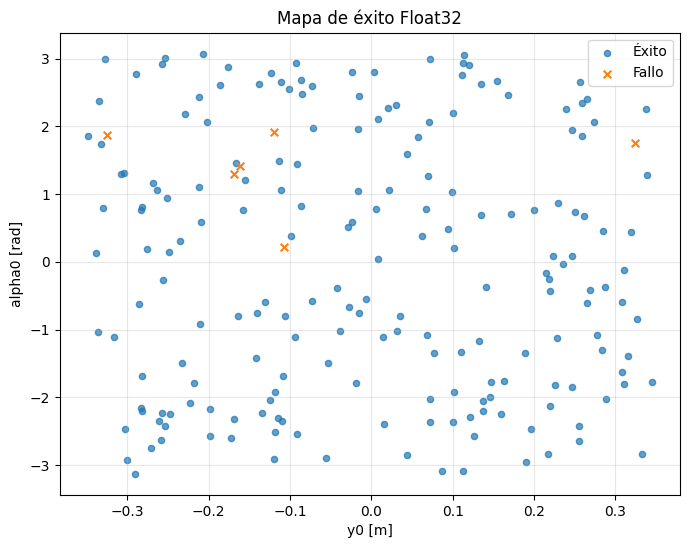

In [19]:
print("Fallos por restricción global:",
      int((~df_runs_float32["constraints_ok"]).sum()))
print("Fallos por criterio final:",
      int((~df_runs_float32["final_state_ok"]).sum()))

ok = df_runs_float32["success"]

plt.figure(figsize=(8,6))
plt.scatter(df_runs_float32.loc[ok,"y0"],
            df_runs_float32.loc[ok,"alpha0"],
            s=20, alpha=0.7, label="Éxito")
plt.scatter(df_runs_float32.loc[~ok,"y0"],
            df_runs_float32.loc[~ok,"alpha0"],
            s=30, marker="x", label="Fallo")
plt.xlabel("y0 [m]")
plt.ylabel("alpha0 [rad]")
plt.title("Mapa de éxito Float32")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 13. Métricas adicionales para la tesis

In [20]:
metricas_extra = {
    "Success_Rate_%": 100*df_runs_float32["success"].mean(),
    "AbsYFinal_media": np.mean(np.abs(df_runs_float32["y_final"])),
    "AbsAlphaFinal_media": np.mean(np.abs(df_runs_float32["alpha_final"])),
    "MaxAbsY_media": df_runs_float32["max_abs_y"].mean(),
    "MaxAbsAlpha_media": df_runs_float32["max_abs_alpha"].mean(),
    "TV_u_media": df_runs_float32["TV_u"].mean(),
    "Sum_u2_media": df_runs_float32["sum_u2"].mean(),
    "Saturaciones_media": df_runs_float32["saturated_samples"].mean()
}
display(pd.DataFrame([metricas_extra], index=["Float32"]))

,Success_Rate_%,AbsYFinal_media,AbsAlphaFinal_media,MaxAbsY_media,MaxAbsAlpha_media,TV_u_media,Sum_u2_media,Saturaciones_media
Float32,97.0,0.026275,0.008088,0.25062,2.756353,111.741036,284.833714,0.295


## 14. Comparación estática opcional con la primera acción MPC del dataset

In [21]:
def rmse(a,b):
    a,b=np.asarray(a),np.asarray(b)
    return float(np.sqrt(np.mean((a-b)**2)))

def mae(a,b):
    a,b=np.asarray(a),np.asarray(b)
    return float(np.mean(np.abs(a-b)))

def max_abs_error(a,b):
    return float(np.max(np.abs(np.asarray(a)-np.asarray(b))))

N_STATIC = 10000

X0_static = pd.read_csv(
    X0_PATH, header=None, nrows=N_STATIC, dtype=np.float32
).to_numpy()

U0_mpc = pd.read_csv(
    U_PATH, header=None, usecols=[0], nrows=N_STATIC, dtype=np.float32
).to_numpy().reshape(-1)

Xn = normalize(X0_static, normalization["x"]).astype(np.float32)
Un = model(jnp.asarray(Xn))
U0_nn = denormalize(np.asarray(Un), normalization["u"]).reshape(-1)
U0_nn = np.clip(U0_nn, -9, 9)

display(pd.DataFrame([{
    "RMSE_u": rmse(U0_mpc, U0_nn),
    "MAE_u": mae(U0_mpc, U0_nn),
    "MaxAbsError_u": max_abs_error(U0_mpc, U0_nn)
}], index=["Float32"]))

,RMSE_u,MAE_u,MaxAbsError_u
Float32,0.375048,0.166331,8.826412


## 15. Exportar baseline

In [22]:
OUTPUT_DIR = Path("resultados_ampc_float32")
OUTPUT_DIR.mkdir(exist_ok=True)

df_runs_float32.to_csv(OUTPUT_DIR/"float32_runs_200.csv", index=False)
pd.DataFrame([resumen_float32]).to_csv(
    OUTPUT_DIR/"float32_success_rate.csv", index=False
)
pd.DataFrame([metricas_extra]).to_csv(
    OUTPUT_DIR/"float32_metricas_extra.csv", index=False
)

print("Guardado en:", OUTPUT_DIR.resolve())

Guardado en: C:\Users\Alonso\Jupyter\Tesis\Test_Modelos_Cuantizacion\Adaptative MPC\resultados_ampc_float32


# 16. Regla para las futuras cuantizaciones

Para PTQ, QAT, INT16x8 o Mixed Precision se deben conservar **sin cambios**:

- `X0_TEST`;
- 200 condiciones iniciales;
- semilla `PRNGKey(100)`;
- \(T_s=0.16\) s;
- 100 pasos / 16 s;
- misma dinámica;
- mismo `odeint`;
- clip \([-9,9]\);
- `check_constraints_original()`;
- `check_final_state_constraints_original()`.

Así, cualquier cambio en `Success_Rate` puede atribuirse a la representación/cuanti­zación de la red y no a un cambio en el banco de pruebas.

> Nota: el paper también usa una red de sensibilidades de 8 capas para el AMPC adaptativo. Este notebook fija el baseline de la **política nominal \(\pi_{NN}\)** con parámetros nominales. Para reproducir la Figura 3 completa es necesario cargar además `model_8x50_aug` y su `normalization.p`.

# TRANSFERENCIA DE TOPOLOGIA A KERAS

In [24]:
# SE OBSERVA LA TOPOLOGIA ORIGINAL DEL MODELO FLOAT32 PARA TRANSFERIR A KERAS


for i, layer in enumerate(model.neural_network.layers):
    print(
        i,
        layer.weight.shape,
        layer.bias.shape,
        layer.activation_function_name
    )

0 (50, 4) (50,) tanh
1 (50, 50) (50,) tanh
2 (50, 50) (50,) tanh
3 (50, 50) (50,) tanh
4 (50, 50) (50,) tanh
5 (50, 50) (50,) tanh
6 (50, 50) (50,) tanh
7 (1, 50) (1,) linear


In [25]:
import tensorflow as tf

modelo_keras = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,), name="input_state"),

    tf.keras.layers.Dense(50, activation="tanh", name="dense_0"),
    tf.keras.layers.Dense(50, activation="tanh", name="dense_1"),
    tf.keras.layers.Dense(50, activation="tanh", name="dense_2"),
    tf.keras.layers.Dense(50, activation="tanh", name="dense_3"),
    tf.keras.layers.Dense(50, activation="tanh", name="dense_4"),
    tf.keras.layers.Dense(50, activation="tanh", name="dense_5"),
    tf.keras.layers.Dense(50, activation="tanh", name="dense_6"),

    tf.keras.layers.Dense(1, activation=None, name="output_u")
])

modelo_keras.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_0 (Dense)                 │ (None, 50)             │           250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_u (Dense)                │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,601 (60.94 KB)

 Trainable params: 15,601 (60.94 KB)

 Non-trainable params: 0 (0.00 B)

# Transferencia exacta de pesos

En Equinox:

$y=Wx+b$

con:

$W_{eqx}.shape = (out, in)$

En Keras:

$W_{keras}.shape = (in, out)$

Por tanto necesitas transponer:

$W_{keras}=W_{eqx}^{T}$


In [29]:
for i, (layer_eqx, layer_keras) in enumerate(
    zip(
        model.neural_network.layers,
        modelo_keras.layers
    )
):
    W_eqx = np.asarray(layer_eqx.weight, dtype=np.float32)
    b_eqx = np.asarray(layer_eqx.bias, dtype=np.float32)

    W_keras = W_eqx.T

    layer_keras.set_weights([
        W_keras,
        b_eqx
    ])

    print(
        f"Capa {i}: "
        f"EQX {W_eqx.shape} -> "
        f"Keras {W_keras.shape}"
    )

Capa 0: EQX (50, 4) -> Keras (4, 50)
Capa 1: EQX (50, 50) -> Keras (50, 50)
Capa 2: EQX (50, 50) -> Keras (50, 50)
Capa 3: EQX (50, 50) -> Keras (50, 50)
Capa 4: EQX (50, 50) -> Keras (50, 50)
Capa 5: EQX (50, 50) -> Keras (50, 50)
Capa 6: EQX (50, 50) -> Keras (50, 50)
Capa 7: EQX (1, 50) -> Keras (50, 1)


# Validación obligatoria EQX vs Keras

In [35]:
# Usa estados reales del dataset:
N_TEST_EQUIV = 10000

X_test_equiv = pd.read_csv(
    X0_PATH,
    header=None,
    nrows=N_TEST_EQUIV,
    dtype=np.float32
).to_numpy()


#Primero normalizas igual que el modelo original:
X_norm = normalize(
    X_test_equiv,
    normalization["x"]
).astype(np.float32)

#Inferencia Equinox:
U_eqx_norm = np.asarray(
    model(jnp.asarray(X_norm))
).reshape(-1)

#Inferencia Keras:
U_keras_norm = modelo_keras.predict(
    X_norm,
    verbose=0
).reshape(-1)

#calculamos
error = U_keras_norm - U_eqx_norm

rmse_eqx_keras = np.sqrt(
    np.mean(error**2)
)

mae_eqx_keras = np.mean(
    np.abs(error)
)

max_error_eqx_keras = np.max(
    np.abs(error)
)
print("----------------NORMALIZADO------------------")
print("RMSE EQX vs Keras:", rmse_eqx_keras)
print("MAE  EQX vs Keras:", mae_eqx_keras)
print("MAX  EQX vs Keras:", max_error_eqx_keras)




U_eqx = denormalize(
    U_eqx_norm,
    normalization["u"]
)

U_keras = denormalize(
    U_keras_norm,
    normalization["u"]
)

U_eqx = np.clip(U_eqx, -9, 9)
U_keras = np.clip(U_keras, -9, 9)


#calculamos
error = U_keras  - U_eqx

rmse_eqx_keras = np.sqrt(
    np.mean(error**2)
)

mae_eqx_keras = np.mean(
    np.abs(error)
)

max_error_eqx_keras = np.max(
    np.abs(error)
)

print("----------------DESNORMALIZADO------------------")
print("RMSE EQX vs Keras:", rmse_eqx_keras)
print("MAE  EQX vs Keras:", mae_eqx_keras)
print("MAX  EQX vs Keras:", max_error_eqx_keras)

----------------NORMALIZADO------------------
RMSE EQX vs Keras: 9.1202736e-07
MAE  EQX vs Keras: 2.58891e-07
MAX  EQX vs Keras: 4.0628016e-05
----------------DESNORMALIZADO------------------
RMSE EQX vs Keras: 8.20341354601202e-06
MAE  EQX vs Keras: 2.3063083409957656e-06
MAX  EQX vs Keras: 0.00036565214761175024


# Validacion 200 condiciones iniciales

In [36]:
def call_control_keras(x):
    x = np.asarray(x, dtype=np.float32).reshape(1, 4)

    x_norm = normalize(
        x,
        normalization["x"]
    ).astype(np.float32)

    u_norm = modelo_keras(
        x_norm,
        training=False
    ).numpy()

    u = denormalize(
        u_norm,
        normalization["u"]
    )

    return np.clip(
        u.reshape(-1),
        -9.0,
        9.0
    )


def simulate_closed_loop_nominal_keras(x0, n_steps=N_SIM):
    X = np.zeros((n_steps+1, 4), dtype=np.float64)
    U = np.zeros(n_steps, dtype=np.float64)
    X[0] = x0

    for k in range(n_steps):
        # Igual que run_tester_round(): sin wrap del ángulo antes del controlador.
        u = call_control_keras(X[k])
        U[k] = float(u[0])
        X[k+1] = sim_nominal.run(X[k], np.array([U[k]]))
    return X, U



def evaluar_success_rate_float32(X0_test=X0_TEST):
    registros = []
    exitos = 0
    t0 = time.perf_counter()

    for i, x0 in enumerate(X0_test):
        X_i, U_i = simulate_closed_loop_nominal_keras(x0)

        c_ok = check_constraints_original(X_i)
        f_ok = check_final_state_constraints_original(X_i)
        ok = c_ok and f_ok
        exitos += int(ok)

        Xm = mod_pendulum_np(X_i)

        registros.append({
            "id": i,
            "success": ok,
            "constraints_ok": c_ok,
            "final_state_ok": f_ok,
            "y0": x0[0],
            "alpha0": x0[1],
            "y_final": Xm[-1,0],
            "alpha_final": Xm[-1,1],
            "ydot_final": Xm[-1,2],
            "alphadot_final": Xm[-1,3],
            "max_abs_y": np.max(np.abs(Xm[:,0])),
            "max_abs_alpha": np.max(np.abs(Xm[:,1])),
            "u_min": np.min(U_i),
            "u_max": np.max(U_i),
            "saturated_samples": int(np.sum(np.isclose(np.abs(U_i), 9.0, atol=1e-5))),
            "sum_u2": float(np.sum(U_i**2)),
            "TV_u": float(np.sum(np.abs(np.diff(U_i))))
        })

    elapsed = time.perf_counter() - t0
    df = pd.DataFrame(registros)
    resumen = {
        "Modelo": "Float32_keras",
        "N": len(X0_test),
        "Éxitos": exitos,
        "Fallos": len(X0_test)-exitos,
        "Success_Rate": exitos/len(X0_test),
        "Success_Rate_%": 100*exitos/len(X0_test),
        "Tiempo_evaluacion_s": elapsed
    }
    return df, resumen


In [37]:
X0_DEMO = np.array([0.0, np.pi, 0.0, 0.0])
X_demo, U_demo = simulate_closed_loop_nominal_keras(X0_DEMO)
print("----RESULTADOS MODELO KERAS------")
print("Estado final:", X_demo[-1])
print("Restricción global:", check_constraints_original(X_demo))
print("Criterio final:", check_final_state_constraints_original(X_demo))
print("ÉXITO:", success_original(X_demo))

----RESULTADOS MODELO KERAS------
Estado final: [ 0.00581  -0.009519 -0.11026   0.162613]
Restricción global: True
Criterio final: True
ÉXITO: True


In [38]:
df_runs_float32, resumen_float32_keras = evaluar_success_rate_float32()
display(pd.DataFrame([resumen_float32_keras]))

,Modelo,N,Éxitos,Fallos,Success_Rate,Success_Rate_%,Tiempo_evaluacion_s
0,Float32_keras,200,199,1,0.995,99.5,223.232519
